In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
from sklearn.utils.class_weight import compute_class_weight

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
data_dir = os.path.join(path, "chest_xray")

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.


In [9]:
!pip install -q kagglehub

In [10]:
train_dir = os.path.join(data_dir, "train")
val_dir = os.path.join(data_dir, "val")
test_dir = os.path.join(data_dir, "test")

SIZE_IMG = (180, 180)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=SIZE_IMG,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=SIZE_IMG,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=SIZE_IMG,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary"
)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.


In [11]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

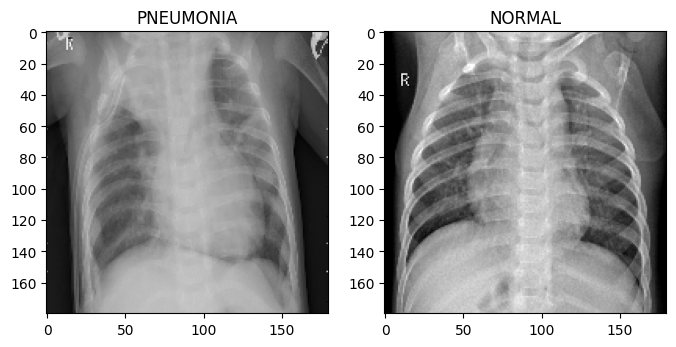

In [12]:
class_names = ["NORMAL", "PNEUMONIA"]
plt.figure(figsize=(8, 4))

for images, labels in train_ds.take(1):
    for i in range(2):
        ax = plt.subplot(1, 2, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[int(labels[i])])
plt.show()

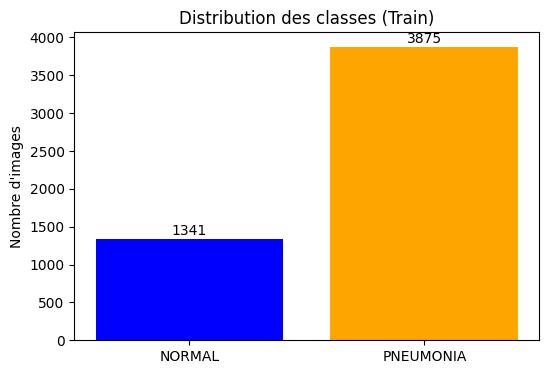

In [13]:
import os
import glob

num_normal = len(glob.glob(os.path.join(train_dir, "NORMAL", "*")))
num_pneumonia = len(glob.glob(os.path.join(train_dir, "PNEUMONIA", "*")))

counts = {"NORMAL": num_normal, "PNEUMONIA": num_pneumonia}
classes = list(counts.keys())
values = list(counts.values())

plt.figure(figsize=(6, 4))
plt.bar(classes, values, color=["blue", "orange"])
plt.title("Distribution des classes (Train)")
plt.ylabel("Nombre d'images")
for i, v in enumerate(values):
    plt.text(i, v + 50, str(v), ha="center")
plt.show()

In [14]:
y_train = []
for _, labels in train_ds:
    y_train.extend(labels.numpy().flatten())
y_train = np.array(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
weight_dict = {i: weight for i, weight in enumerate(class_weights)}
print("Poids des classes :", weight_dict)

Poids des classes : {0: np.float64(1.9448173005219984), 1: np.float64(0.6730322580645162)}


In [15]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [16]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(180, 180, 3)),
    data_augmentation,

    tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

In [17]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,988,769 (15.22 MB)

 Trainable params: 3,988,769 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
import time

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6
)


history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=weight_dict,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 37s 176ms/step - accuracy: 0.7019 - loss: 0.5050 - precision: 0.9039 - recall: 0.6699 - val_accuracy: 0.8750 - val_loss: 0.5069 - val_precision: 0.8750 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 187ms/step - accuracy: 0.8742 - loss: 0.2945 - precision: 0.9579 - recall: 0.8689 - val_accuracy: 0.8125 - val_loss: 0.4011 - val_precision: 0.8571 - val_recall: 0.7500 - learning_rate: 0.0010
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 182ms/step - accuracy: 0.9005 - loss: 0.2467 - precision: 0.9671 - recall: 0.8965 - val_accuracy: 0.7500 - val_loss: 0.4164 - val_precision: 0.7500 - val_recall: 0.7500 - learning_rate: 0.0010
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 42s 187ms/step - accuracy: 0.9166 - loss: 0.2108 - precision: 0.9733 - recall: 0.9128 - val_accuracy: 0.8125 - val_loss: 0.3814 - val_precision: 0.7273 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 193ms/step - 

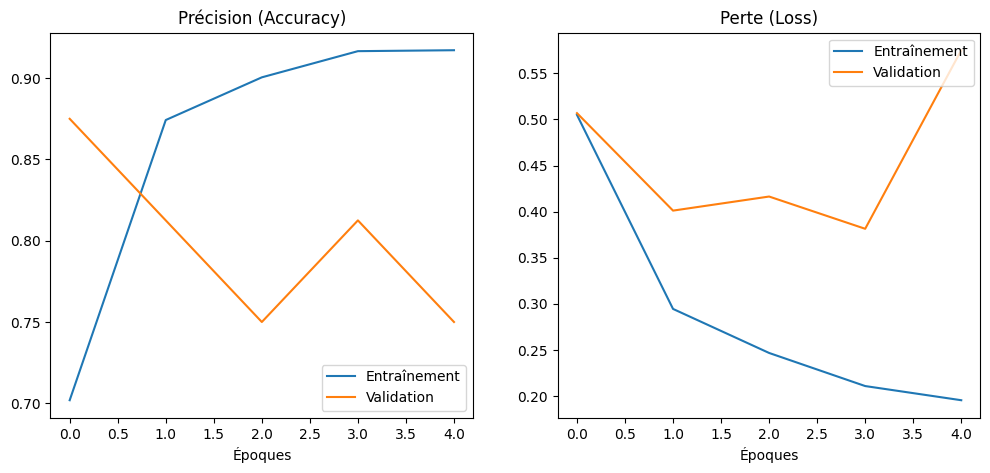

In [19]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Entraînement')
plt.plot(epochs_range, val_acc, label='Validation')
plt.legend(loc='lower right')
plt.title('Précision (Accuracy)')
plt.xlabel('Époques')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Entraînement')
plt.plot(epochs_range, val_loss, label='Validation')
plt.legend(loc='upper right')
plt.title('Perte (Loss)')
plt.xlabel('Époques')

plt.show()

In [20]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score
import seaborn as sns

test_loss, test_acc, test_precision, test_recall = model.evaluate(test_ds)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 232ms/step - accuracy: 0.8846 - loss: 0.2845 - precision: 0.9077 - recall: 0.9077
Test Loss: 0.2845
Test Accuracy: 0.8846
Test Precision: 0.9077
Test Recall: 0.9077


In [21]:
y_true = []
y_pred_probs = []

for images, labels in test_ds:
    y_true.extend(labels.numpy().flatten())
    preds = model.predict(images, verbose=0)
    y_pred_probs.extend(preds.flatten())

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
y_pred = (y_pred_probs > 0.5).astype(int)

test_f1 = f1_score(y_true, y_pred)
test_auc = roc_auc_score(y_true, y_pred_probs)

print(f"Test F1-Score: {test_f1:.4f}")
print(f"Test ROC-AUC: {test_auc:.4f}")

Test F1-Score: 0.9077
Test ROC-AUC: 0.9484


In [22]:
print("\nRapport de classification :")
print(classification_report(y_true, y_pred, target_names=class_names))


Rapport de classification :
              precision    recall  f1-score   support

      NORMAL       0.85      0.85      0.85       234
   PNEUMONIA       0.91      0.91      0.91       390

    accuracy                           0.88       624
   macro avg       0.88      0.88      0.88       624
weighted avg       0.88      0.88      0.88       624



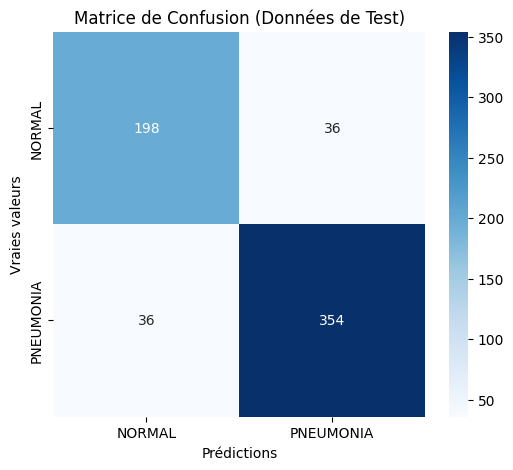

In [23]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Matrice de Confusion (Données de Test)')
plt.xlabel('Prédictions')
plt.ylabel('Vraies valeurs')
plt.show()

In [24]:
test_images_all = []
for images, _ in test_ds:
    test_images_all.append(images.numpy())
test_images_all = np.concatenate(test_images_all, axis=0)

idx_tp = np.where((y_true == 1) & (y_pred == 1))[0]
idx_tn = np.where((y_true == 0) & (y_pred == 0))[0]
idx_fp = np.where((y_true == 0) & (y_pred == 1))[0]
idx_fn = np.where((y_true == 1) & (y_pred == 0))[0]

print(f"Vrais Positifs (Pneumonie détectée correctement) : {len(idx_tp)}")
print(f"Vrais Négatifs (Normal détecté correctement) : {len(idx_tn)}")
print(f"Faux Positifs (Sain prédit comme Pneumonie) : {len(idx_fp)}")
print(f"Faux Négatifs (Pneumonie non détectée) : {len(idx_fn)}")

Vrais Positifs (Pneumonie détectée correctement) : 354
Vrais Négatifs (Normal détecté correctement) : 198
Faux Positifs (Sain prédit comme Pneumonie) : 36
Faux Négatifs (Pneumonie non détectée) : 36


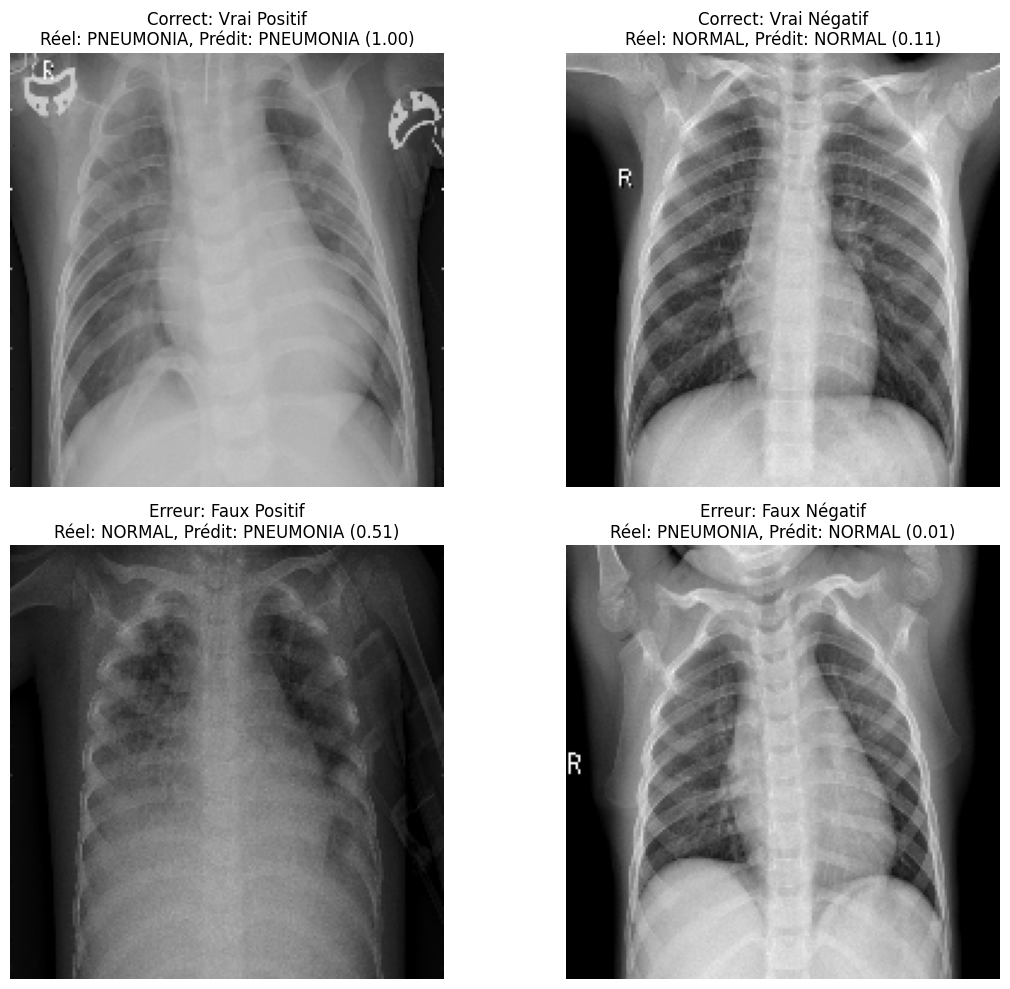

In [25]:
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
if len(idx_tp) > 0:
    idx = idx_tp[0]
    plt.imshow(test_images_all[idx])
    plt.title(f"Correct: Vrai Positif\nRéel: PNEUMONIA, Prédit: PNEUMONIA ({y_pred_probs[idx]:.2f})")
plt.axis('off')

plt.subplot(2, 2, 2)
if len(idx_tn) > 0:
    idx = idx_tn[0]
    plt.imshow(test_images_all[idx])
    plt.title(f"Correct: Vrai Négatif\nRéel: NORMAL, Prédit: NORMAL ({y_pred_probs[idx]:.2f})")
plt.axis('off')

plt.subplot(2, 2, 3)
if len(idx_fp) > 0:
    idx = idx_fp[0]
    plt.imshow(test_images_all[idx])
    plt.title(f"Erreur: Faux Positif\nRéel: NORMAL, Prédit: PNEUMONIA ({y_pred_probs[idx]:.2f})")
plt.axis('off')

plt.subplot(2, 2, 4)
if len(idx_fn) > 0:
    idx = idx_fn[0]
    plt.imshow(test_images_all[idx])
    plt.title(f"Erreur: Faux Négatif\nRéel: PNEUMONIA, Prédit: NORMAL ({y_pred_probs[idx]:.2f})")
plt.axis('off')

plt.tight_layout()
plt.show()

In [26]:
import json

model_path = "pneumonia_detector.keras"
model.save(model_path)
print(f"Modèle sauvegardé avec succès sous : {model_path}")

config_metadata = {
    "image_size": SIZE_IMG,
    "class_names": class_names
}

config_path = "model_config.json"
with open(config_path, "w") as f:
    json.dump(config_metadata, f, indent=4)
print(f"Configuration sauvegardée sous : {config_path}")

Modèle sauvegardé avec succès sous : pneumonia_detector.keras
Configuration sauvegardée sous : model_config.json


In [27]:
reloaded_model = tf.keras.models.load_model(model_path)
print("Modèle rechargé avec succès sans nouvel entraînement.")

Modèle rechargé avec succès sans nouvel entraînement.


In [28]:
def predict_xray(image_path):
    try:
        img = tf.keras.utils.load_img(image_path, target_size=SIZE_IMG, color_mode="rgb")
        img_array = tf.keras.utils.img_to_array(img)

        img_array = img_array / 255.0

        img_array = np.expand_dims(img_array, axis=0)

        prediction_score = reloaded_model.predict(img_array, verbose=0)[0][0]

        predicted_class = "PNEUMONIA" if prediction_score > 0.5 else "NORMAL"

        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.title(f"Classe Prédite: {predicted_class}\nScore PNEUMONIA: {prediction_score:.4f}")
        plt.axis('off')
        plt.show()

        return predicted_class, prediction_score
    except Exception as e:
        print(f"Erreur lors du traitement ou de la prédiction : {e}")
        return None, None

--- Test sur une image Saine (NORMAL) ---


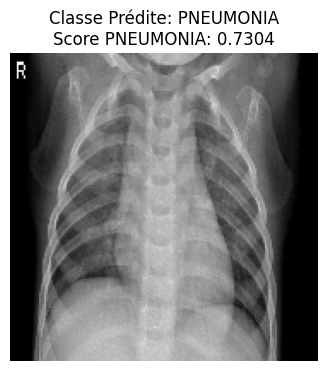

--- Test sur une image de Pneumonie (PNEUMONIA) ---


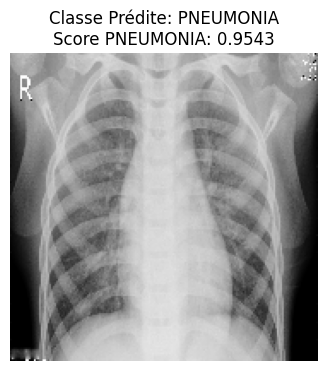

In [29]:
import glob

test_normal_images = glob.glob(os.path.join(test_dir, "NORMAL", "*"))
test_pneumonia_images = glob.glob(os.path.join(test_dir, "PNEUMONIA", "*"))

print("--- Test sur une image Saine (NORMAL) ---")
if test_normal_images:
    predict_xray(test_normal_images[0])

print("--- Test sur une image de Pneumonie (PNEUMONIA) ---")
if test_pneumonia_images:
    predict_xray(test_pneumonia_images[0])

feature axtraction

In [41]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)


In [31]:
y_train = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in train_ds
]).astype(int)

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

Class weights: {0: 1.9448173005219984, 1: 0.6730322580645162}


In [32]:
def build_transfer_model():
    # Data augmentation
    data_augmentation = tf.keras.Sequential([
        layers.RandomRotation(0.02),
        layers.RandomZoom(0.05)
    ], name="data_augmentation")

    # Modèle préentraîné
    base_model = MobileNetV2(
        weights="imagenet",
        include_top=False,
        input_shape=(180, 180, 3)
    )

    # Geler les couches préentraînées
    base_model.trainable = False

    # Entrée : pixels RGB entre 0 et 255
    inputs = layers.Input(shape=(180, 180, 3))

    x = data_augmentation(inputs)

    # Prétraitement spécifique à MobileNetV2
    x = layers.Lambda(
        preprocess_input,
        name="mobilenet_preprocessing"
    )(x)

    # Garder MobileNetV2 en mode inférence
    x = base_model(x, training=False)

    # Classification binaire
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid",
        name="pneumonia_output"
    )(x)

    model = Model(inputs, outputs)

    return model, base_model


model, base_model = build_transfer_model()

model.summary()

/tmp/ipykernel_557/707630654.py:9: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 180, 180, 3)    │             0 │
│ (Lambda)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_output (Dense)        │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [33]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [34]:
callbacks_feature = [
    ModelCheckpoint(
        "best_mobilenet_feature.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history_feature = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=callbacks_feature
)

Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.5094 - loss: 0.7249 - precision: 0.7460 - recall: 0.5125
Epoch 1: val_loss improved from None to 0.68041, saving model to best_mobilenet_feature.keras

Epoch 1: finished saving model to best_mobilenet_feature.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 37s 197ms/step - accuracy: 0.5107 - loss: 0.7194 - precision: 0.7510 - recall: 0.5107 - val_accuracy: 0.5625 - val_loss: 0.6804 - val_precision: 0.5333 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step - accuracy: 0.5237 - loss: 0.7120 - precision: 0.7546 - recall: 0.5292
Epoch 2: val_loss improved from 0.68041 to 0.67689, saving model to best_mobilenet_feature.keras

Epoch 2: finished saving model to best_mobilenet_feature.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 192ms/step - accuracy: 0.5289 - loss: 0.7080 - precision: 0.7591 - recall: 0.5360 - val_accuracy: 0.5625 - val_loss: 0.6769 - val_precision: 0.5333 - val_recall: 1.0000 - l

fine tuning

In [35]:
# Débloquer le modèle de base
base_model.trainable = True

# Garder les premières couches gelées
fine_tune_at = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Débloquer les dernières couches,
# mais garder BatchNormalization gelées
for layer in base_model.layers[fine_tune_at:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

# Vérifier le nombre de couches entraînables
print(
    "Couches entraînables :",
    sum(layer.trainable for layer in base_model.layers)

)

Couches entraînables : 19


In [36]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [37]:
callbacks_finetuning = [
    ModelCheckpoint(
        "best_mobilenet_finetuned.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_finetuning = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks_finetuning
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - accuracy: 0.6340 - loss: 0.6291 - precision: 0.8403 - recall: 0.6244
Epoch 1: val_loss improved from None to 0.61786, saving model to best_mobilenet_finetuned.keras

Epoch 1: finished saving model to best_mobilenet_finetuned.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 38s 196ms/step - accuracy: 0.6382 - loss: 0.6321 - precision: 0.8367 - recall: 0.6374 - val_accuracy: 0.6250 - val_loss: 0.6179 - val_precision: 0.5714 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step - accuracy: 0.6560 - loss: 0.6200 - precision: 0.8410 - recall: 0.6621
Epoch 2: val_loss did not improve from 0.61786
163/163 ━━━━━━━━━━━━━━━━━━━━ 39s 187ms/step - accuracy: 0.6670 - loss: 0.6144 - precision: 0.8503 - recall: 0.6697 - val_accuracy: 0.5625 - val_loss: 0.6264 - val_precision: 0.5333 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.6698 - loss: 

Évaluation finale sur le test

In [45]:
# Charger le meilleur modèle de fine-tuning avec la fonction custom_objects pour résoudre preprocess_input
best_model = tf.keras.models.load_model(
    "best_mobilenet_finetuned.keras",
    custom_objects={"preprocess_input": preprocess_input}
)

# Évaluation finale
test_results = best_model.evaluate(
    test_ds,
    return_dict=True
)

print("\nRésultats sur le test :")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

# Prédictions
y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for _, labels in test_ds
]).astype(int)

y_prob = best_model.predict(test_ds).reshape(-1)
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification Report :")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        zero_division=0
    )
)

print("Confusion Matrix :")
print(confusion_matrix(y_true, y_pred))

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 150ms/step - accuracy: 0.7644 - loss: 0.5079 - precision: 0.9263 - recall: 0.6769

Résultats sur le test :
accuracy: 0.7644
loss: 0.5079
precision: 0.9263
recall: 0.6769
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 167ms/step

Classification Report :
              precision    recall  f1-score   support

      NORMAL       0.38      0.55      0.45       234
   PNEUMONIA       0.63      0.46      0.53       390

    accuracy                           0.50       624
   macro avg       0.51      0.51      0.49       624
weighted avg       0.54      0.50      0.50       624

Confusion Matrix :
[[129 105]
 [210 180]]


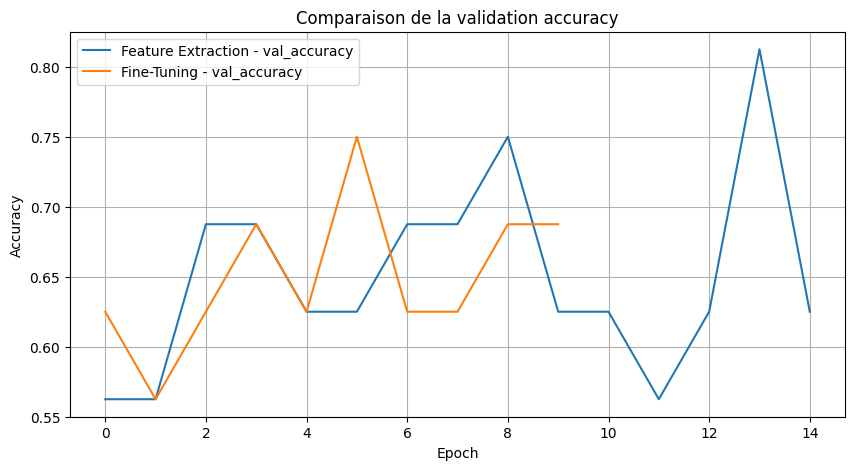

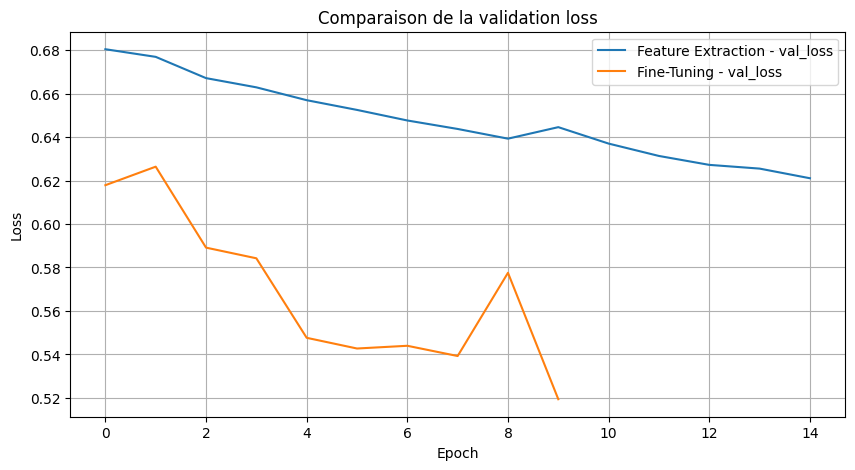

In [46]:
def compare_histories(history_feature, history_finetuning):
    histories = {
        "Feature Extraction": history_feature,
        "Fine-Tuning": history_finetuning
    }

    plt.figure(figsize=(10, 5))

    for name, history in histories.items():
        plt.plot(
            history.history["val_accuracy"],
            label=f"{name} - val_accuracy"
        )

    plt.title("Comparaison de la validation accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(10, 5))

    for name, history in histories.items():
        plt.plot(
            history.history["val_loss"],
            label=f"{name} - val_loss"
        )

    plt.title("Comparaison de la validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()


compare_histories(history_feature, history_finetuning)